In [1]:
#data manipulation
import pandas as pd
import numpy as np

#viz
import seaborn as sns
import matplotlib.pyplot as plt

#NLP
import re
import nltk
import string
from nltk import sent_tokenize, word_tokenize
from nltk.tokenize.toktok import ToktokTokenizer
from bs4 import BeautifulSoup
import spacy
from nltk.stem import WordNetLemmatizer

%matplotlib inline

#MISC
import warnings
warnings.filterwarnings('ignore')
import unicodedata
from tqdm import tqdm

In [2]:
#Reading  data files
df = pd.read_csv(r"train.csv")

In [3]:
TAG_RE = re.compile(r'<[^>]+>') # remove <br> and other html tags

def clean_text(text):
    # lower text
    text = text.lower()

    # Reemove Html Tags like <br>
    text= TAG_RE.sub('', text)

    # remove puncutation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # tokenize_text
    text = [word for word in word_tokenize(text)]

    # remove words that contain numbers
    text = [word for word in text if not any(c.isdigit() for c in word)]
    
    # remove empty tokens
    text = [t for t in text if len(t) > 0]

    # remove words with only one letter
    text = [t for t in text if len(t) > 1]

    # join all
    text = " ".join(text)
    return(text)

In [4]:
df["comments_clean"] = df["comment_text"].apply(lambda x: clean_text(x))

In [5]:
df = df.replace(r'^(\s?)+$',np.nan,regex=True)
df = df[df['comments_clean'].notna()]
df.reset_index(inplace= True)

In [6]:
# Let's create another column "bad_comment" denoting any type of toxicity in the comment

df["bad_comment"] = df.iloc[:,2:].sum(axis = 1)
df["bad_comment"][df["bad_comment"] != 0] = 1

In [7]:
from sklearn.model_selection import train_test_split

train_corpus, test_corpus, train_toxic, test_toxic, train_severe_toxic, test_severe_toxic, train_obscene, test_obscene, train_threat, test_threat,train_insult, test_insult, train_identity_hate, test_identity_hate, train_bad_comment, test_bad_comment= train_test_split(np.array(df['comments_clean']),
                                       np.array(df['toxic']),np.array(df['severe_toxic']),np.array(df['obscene']),np.array(df['threat']),np.array(df['insult']),np.array(df['identity_hate']),np.array(df['bad_comment']),test_size=0.3, random_state=42)

# Word2Vec

In [8]:
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

In [9]:
tqdm.pandas(desc="progress-bar")
# Function for tokenizing
def tokenize_text(text):
    tokens = []
    for sent in nltk.sent_tokenize(text):
        for word in nltk.word_tokenize(sent):
            if len(word) < 2:
                continue
            tokens.append(word.lower())
    return tokens

In [10]:
train_documents = []
test_documents = []

for comment,tag in zip(train_corpus,train_bad_comment):
    train_documents.append(TaggedDocument(words=tokenize_text(comment), tags=[tag]))
    
for comment,tag in zip(test_corpus,test_bad_comment):
    test_documents.append(TaggedDocument(words=tokenize_text(comment), tags=[tag]))    

In [11]:
%%time
Model = Doc2Vec(dm=1, workers=4, alpha=0.025, min_alpha=0.001)
Model.build_vocab([x for x in tqdm(train_documents)])

100%|██████████| 111670/111670 [00:00<00:00, 1513083.19it/s]


Wall time: 13.6 s


In [12]:
%%time
Model.train(train_documents,total_examples=len(train_corpus),epochs=30)

Wall time: 8min 24s


In [19]:
def vector_for_learning(model, input_docs):
    sents = input_docs
    targets, feature_vectors = zip(*[(doc.tags[0], model.infer_vector(doc.words, steps=20)) for doc in sents])
    return targets, feature_vectors

In [21]:
Model.save('movieModel.d2v')

In [22]:
y_train, X_train = vector_for_learning(Model, train_documents)
y_test, X_test = vector_for_learning(Model, test_documents)

In [23]:
%%time
from sklearn.metrics import confusion_matrix

# Logistic Regression
from sklearn.linear_model import LogisticRegression
Test_lr_dv = LogisticRegression(random_state = 0)
Test_lr_dv.fit(X_train,y_train)

Wall time: 1.14 s


LogisticRegression(random_state=0)

In [28]:
%%time
Test_lr_dv_pred = Test_lr_dv.predict(X_test)

Wall time: 75.8 ms


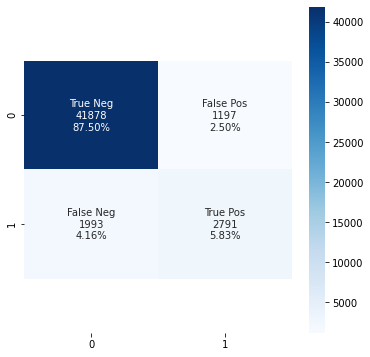

              precision    recall  f1-score   support

           0       0.95      0.97      0.96     43075
           1       0.70      0.58      0.64      4784

    accuracy                           0.93     47859
   macro avg       0.83      0.78      0.80     47859
weighted avg       0.93      0.93      0.93     47859

Wall time: 363 ms


In [33]:
%%time
from sklearn.metrics import classification_report
# Plotting Confusion Matrix
cf_matrix = confusion_matrix(y_test,Test_lr_dv_pred)

grods_names = ['True Neg','False Pos','False Neg','True Pos']

grods_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

grods_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(grods_names,grods_counts,grods_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

print(classification_report(y_test,Test_lr_dv_pred))

In [30]:
%%time
# Naive Bayes
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB(alpha=1)
mnb.fit(X_train,y_train)
mnb_dv_pred = mnb.predict(X_test)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(y_test,mnb_dv_pred)

grods_names = ['True Neg','False Pos','False Neg','True Pos']

grods_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

grods_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(grods_names,grods_counts,grods_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

accuracy= np.trace(cf_matrix)/float(np.sum(cf_matrix))
precision= cf_matrix[1,1]/sum(cf_matrix[:,1])
recall = cf_matrix[1,1]  /  sum(cf_matrix[1,:])
f1_score  = 2*precision*recall / (precision + recall)
stats_text = "\n\nAccuracy={:0.3f}\nPrecision={:0.3f}\nRecall={:0.3f}\nF1 Score={:0.3f}".format(
accuracy,precision,recall,f1_score)
print(stats_text)

ValueError: Negative values in data passed to MultinomialNB (input X)

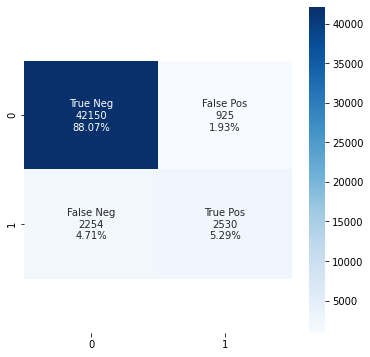

              precision    recall  f1-score   support

           0       0.95      0.98      0.96     43075
           1       0.73      0.53      0.61      4784

    accuracy                           0.93     47859
   macro avg       0.84      0.75      0.79     47859
weighted avg       0.93      0.93      0.93     47859

Wall time: 41.8 s


In [34]:
%%time
# SVM
from sklearn.svm import LinearSVC

svm = LinearSVC(penalty='l2', C=1, random_state=42)
svm.fit(X_train,y_train)
svm_dv_pred =svm.predict(X_test)

# Plotting Confusion Matrix
cf_matrix = confusion_matrix(y_test,svm_dv_pred)

grods_names = ['True Neg','False Pos','False Neg','True Pos']

grods_counts = ["{0:0.0f}".format(value) for value in cf_matrix.flatten()]

grods_percentages = ["{0:.2%}".format(value) for value in cf_matrix.flatten()/np.sum(cf_matrix)]

labels = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(grods_names,grods_counts,grods_percentages)]

labels = np.asarray(labels).reshape(2,2)

plt.figure(figsize=(6,6))
ax = sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues')
bottom, top = ax.get_ylim()
ax.set_ylim(bottom+0.5,top-0.5)
plt.show()

print(classification_report(y_test,svm_dv_pred))

In [37]:
from sklearn.model_selection import cross_val_score
scores = []
classifier =LinearSVC(penalty='l2', C=1, random_state=42)

cv_score = np.mean(cross_val_score(classifier, X_train,y_train, cv=5, scoring='roc_auc'))
scores.append(cv_score)
print('CV score is {}'.format(cv_score))

CV score foris 0.9379391248938764
